In [1]:
import os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titleweight": "bold"})
os.makedirs("outputs", exist_ok=True)

def save(fig, name):
    fig.savefig(f"outputs/{name}.png", dpi=150, bbox_inches="tight")

DATA_PATH = "Dataset Course Enrollment.csv"
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (1563, 7)


,academic_year,semester,school,jae_course_code,course_name,gender,enrolment
0,2013,S1,SCHOOL OF BUSINESS MANAGEMENT,C46,DIPLOMA IN FOOD & BEVERAGE BUSINESS,FEMALE,103
1,2013,S1,SCHOOL OF BUSINESS MANAGEMENT,C46,DIPLOMA IN FOOD & BEVERAGE BUSINESS,MALE,41
2,2013,S1,SCHOOL OF BUSINESS MANAGEMENT,C56,DIPLOMA IN FUND MANAGEMENT & ADMINISTRATION,FEMALE,88
3,2013,S1,SCHOOL OF BUSINESS MANAGEMENT,C56,DIPLOMA IN FUND MANAGEMENT & ADMINISTRATION,MALE,97
4,2013,S1,SCHOOL OF BUSINESS MANAGEMENT,C67,DIPLOMA IN HOSPITALITY & TOURISM MANAGEMENT,FEMALE,376


In [2]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1563 entries, 0 to 1562
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   academic_year    1563 non-null   int64 
 1   semester         1563 non-null   object
 2   school           1563 non-null   object
 3   jae_course_code  1517 non-null   object
 4   course_name      1563 non-null   object
 5   gender           1563 non-null   object
 6   enrolment        1563 non-null   int64 
dtypes: int64(2), object(5)
memory usage: 85.6+ KB


In [3]:
df = raw.copy()
df.columns = df.columns.str.strip().str.lower()
for c in ["semester", "school", "jae_course_code", "course_name", "gender"]:
    df[c] = df[c].astype("string").str.strip().str.upper()

# 1) standardise gender
df["gender"] = df["gender"].str[0]          # FEMALE/F -> F, MALE/M -> M
print("Gender labels:", df["gender"].unique().tolist())

# 2) data-quality checks
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate (year, course, gender) keys:", df.duplicated(["academic_year", "course_name", "gender"]).sum())
print("Semester values:", df["semester"].unique().tolist())
print("Rows with enrolment = 0:", (df["enrolment"] == 0).sum())

Gender labels: ['F', 'M']

Missing values:
 academic_year       0
semester            0
school              0
jae_course_code    46
course_name         0
gender              0
enrolment           0
dtype: int64

Duplicate rows: 0
Duplicate (year, course, gender) keys: 0
Semester values: ['S1']
Rows with enrolment = 0: 25


In [4]:
# 3) zero-enrolment rows: is the whole programme-year zero, or just one gender?
#    (a zero for one gender in a running programme is real data, so these rows are KEPT)
by_cy = df.groupby(["course_name", "academic_year"])["enrolment"].sum()
print("Programme-years with total enrolment = 0:", (by_cy == 0).sum(), "of", len(by_cy))
df[df["enrolment"] == 0].head(10)

Programme-years with total enrolment = 0: 0 of 782


,academic_year,semester,school,jae_course_code,course_name,gender,enrolment
11,2013,S1,SCHOOL OF BUSINESS MANAGEMENT,C93,DIPLOMA IN MEDIA STUDIES & MANAGEMENT,M,0
29,2013,S1,SCHOOL OF CHEMICAL & LIFE SCIENCES,C69,DIPLOMA IN FOOD SCIENCE,M,0
528,2017,S1,SCHOOL OF ENGINEERING,C88,DIPLOMA IN MANUFACTURING ENGINEERING,F,0
554,2017,S1,SCHOOL OF INFORMATION TECHNOLOGY,C54,DIPLOMA IN INFORMATION SECURITY,F,0
576,2017,S1,SCHOOL OF INTERACTIVE & DIGITAL MEDIA,C61,DIPLOMA IN DIGITAL MEDIA DESIGN (ANIMATION),F,0
580,2017,S1,SCHOOL OF INTERACTIVE & DIGITAL MEDIA,C70,DIPLOMA IN DIGITAL ENTERTAINMENT TECHNOLOGY (G...,F,0
598,2018,S1,SCHOOL OF BUSINESS MANAGEMENT,C96,DIPLOMA IN BANKING & FINANCIAL SERVICES,F,0
661,2018,S1,SCHOOL OF HEALTH SCIENCES,<NA>,DIPLOMA IN DIAGNOSTIC RADIOGRAPHY,M,0
672,2018,S1,SCHOOL OF HEALTH SCIENCES,<NA>,DIPLOMA IN PHYSIOTHERAPY,F,0
781,2019,S1,SCHOOL OF HEALTH SCIENCES,C72,DIPLOMA IN DENTAL HYGIENE & THERAPY,M,0


In [5]:
# Programme-year table (one row per programme per year, genders combined)
g = (df.pivot_table(index=["course_name", "academic_year"], columns="gender",
                    values="enrolment", aggfunc="sum", fill_value=0)
       .reset_index())
g["total"] = g["F"] + g["M"]
g["female_share"] = g["F"] / g["total"].replace(0, np.nan)

sch = (df.sort_values("academic_year").groupby(["course_name", "academic_year"])["school"]
         .first().reset_index())
panel = g.merge(sch, on=["course_name", "academic_year"])

# Programmes that did not really run (total = 0) are removed from the panel
panel = panel[panel["total"] > 0].sort_values(["course_name", "academic_year"]).reset_index(drop=True)

# latest school of each programme (handles the school re-organisation)
latest_school = panel.sort_values("academic_year").groupby("course_name")["school"].last()
panel["school_latest"] = panel["course_name"].map(latest_school)

YEARS = list(range(int(panel.academic_year.min()), int(panel.academic_year.max()) + 1))
print("Panel shape:", panel.shape, "| years:", YEARS[0], "-", YEARS[-1], "| programmes:", panel.course_name.nunique())
panel.head()

Panel shape: (782, 8) | years: 2013 - 2026 | programmes: 94


,course_name,academic_year,F,M,total,female_share,school,school_latest
0,AEROSPACE/ ELECTRICAL/ ELECTRONICS PROGRAMME,2016,19,77,96,0.197917,SCHOOL OF ENGINEERING,SCHOOL OF ENGINEERING
1,AEROSPACE/ ELECTRICAL/ ELECTRONICS PROGRAMME,2017,15,73,88,0.170455,SCHOOL OF ENGINEERING,SCHOOL OF ENGINEERING
2,AEROSPACE/ ELECTRICAL/ ELECTRONICS PROGRAMME,2018,15,76,91,0.164835,SCHOOL OF ENGINEERING,SCHOOL OF ENGINEERING
3,AEROSPACE/ ELECTRICAL/ ELECTRONICS PROGRAMME,2019,11,56,67,0.164179,SCHOOL OF ENGINEERING,SCHOOL OF ENGINEERING
4,AEROSPACE/MECHATRONICS PROGRAMME,2015,40,288,328,0.121951,SCHOOL OF ENGINEERING,SCHOOL OF ENGINEERING


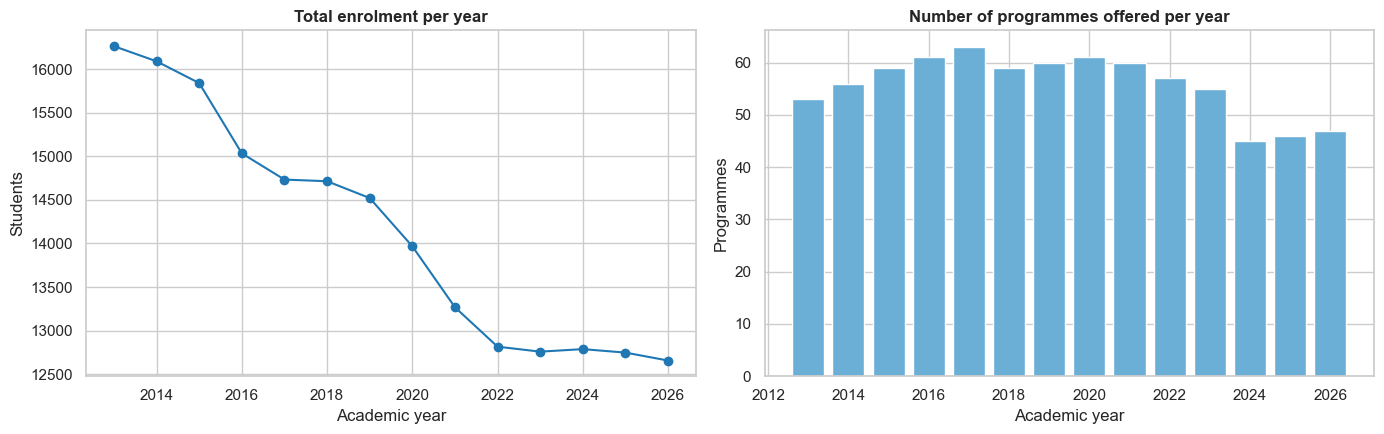

Total enrolment fell from 16,266 (2013) to 12,656 (2026): -22.2%


In [6]:
total_by_year = panel.groupby("academic_year")["total"].sum()
n_courses = panel.groupby("academic_year")["course_name"].nunique()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(total_by_year.index, total_by_year.values, marker="o", color="#1f77b4")
ax[0].set_title("Total enrolment per year"); ax[0].set_xlabel("Academic year"); ax[0].set_ylabel("Students")
ax[1].bar(n_courses.index, n_courses.values, color="#6baed6")
ax[1].set_title("Number of programmes offered per year"); ax[1].set_xlabel("Academic year"); ax[1].set_ylabel("Programmes")
plt.tight_layout(); save(fig, "01_total_and_programmes"); plt.show()

print(f"Total enrolment fell from {total_by_year.iloc[0]:,} ({YEARS[0]}) to {total_by_year.iloc[-1]:,} ({YEARS[-1]}): "
      f"{(total_by_year.iloc[-1]/total_by_year.iloc[0]-1)*100:.1f}%")

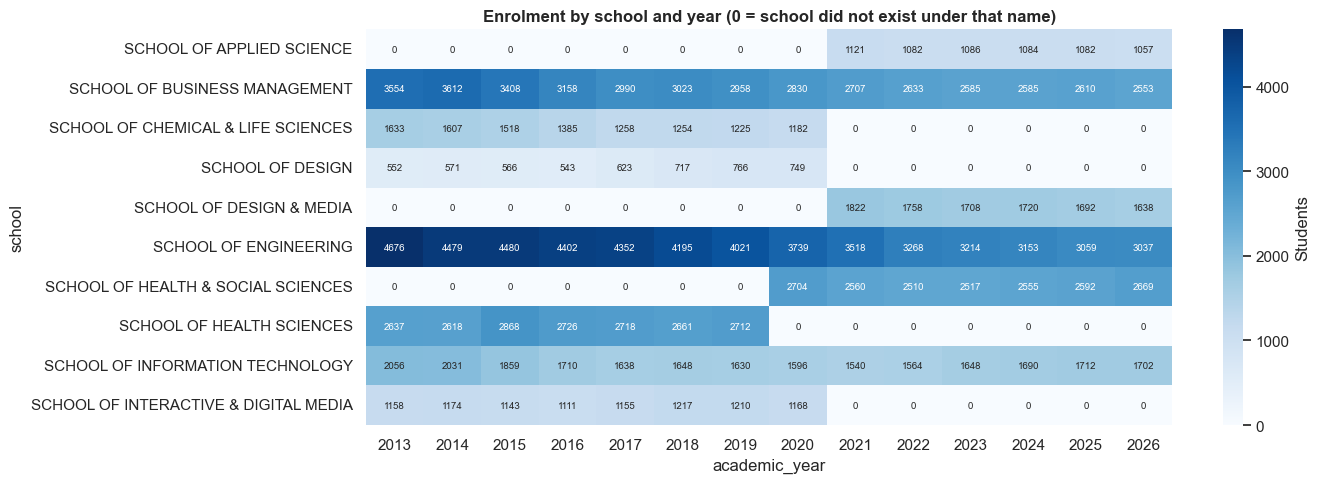

In [7]:
# Enrolment by school and year (school names change over time -> blanks are re-organisations, not zero demand)
sy = panel.pivot_table(index="school", columns="academic_year", values="total", aggfunc="sum")
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(sy.fillna(0), annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "Students"}, ax=ax, annot_kws={"size": 7})
ax.set_title("Enrolment by school and year (0 = school did not exist under that name)")
plt.tight_layout(); save(fig, "02_school_year_heatmap"); plt.show()

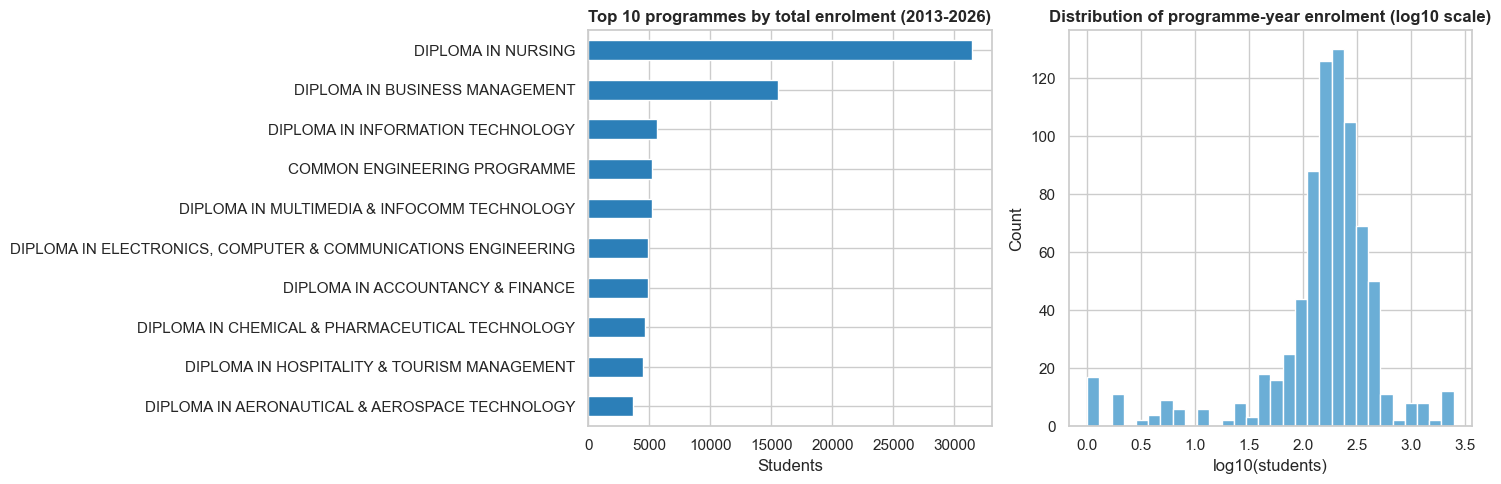

In [8]:
top = panel.groupby("course_name")["total"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
top.head(10).sort_values().plot.barh(ax=ax[0], color="#2c7fb8")
ax[0].set_title("Top 10 programmes by total enrolment (2013-2026)"); ax[0].set_xlabel("Students"); ax[0].set_ylabel("")
ax[1].hist(np.log10(panel["total"]), bins=30, color="#6baed6", edgecolor="white")
ax[1].set_title("Distribution of programme-year enrolment (log10 scale)"); ax[1].set_xlabel("log10(students)"); ax[1].set_ylabel("Count")
plt.tight_layout(); save(fig, "03_top_programmes_distribution"); plt.show()

In [9]:
summary = panel["total"].describe().round(1).to_frame("programme-year enrolment")
display(summary)

yearly = pd.DataFrame({
    "total": total_by_year,
    "programmes": n_courses,
    "avg_per_programme": (total_by_year / n_courses).round(1),
    "yoy_growth_%": (total_by_year.pct_change() * 100).round(2),
})
yearly

,programme-year enrolment
count,782.0
mean,253.5
std,327.0
min,1.0
25%,119.0
50%,184.0
75%,268.8
max,2463.0


,total,programmes,avg_per_programme,yoy_growth_%
academic_year,,,,
2013,16266,53,306.9,NaN
2014,16092,56,287.4,-1.07
2015,15842,59,268.5,-1.55
2016,15035,61,246.5,-5.09
2017,14734,63,233.9,-2.00
2018,14715,59,249.4,-0.13
2019,14522,60,242.0,-1.31
2020,13968,61,229.0,-3.81
2021,13268,60,221.1,-5.01


In [10]:
first_y, last_y = YEARS[0], YEARS[-1]
cmp = panel[panel.academic_year.isin([first_y, last_y])].pivot_table(index="course_name", columns="academic_year", values="total")
cmp = cmp.dropna()
cmp["change"] = cmp[last_y] - cmp[first_y]
cmp["change_%"] = (cmp["change"] / cmp[first_y] * 100).round(1)
print(f"Programmes offered in both {first_y} and {last_y}: {len(cmp)}")
print("\nBiggest increases"); display(cmp.sort_values("change", ascending=False).head(5))
print("Biggest decreases"); display(cmp.sort_values("change").head(5))

Programmes offered in both 2013 and 2026: 16

Biggest increases


academic_year,2013,2026,change,change_%
course_name,,,,
DIPLOMA IN NURSING,1837.0,2463.0,626.0,34.1
DIPLOMA IN BIOMEDICAL ENGINEERING,166.0,227.0,61.0,36.7
DIPLOMA IN FOOD & BEVERAGE BUSINESS,144.0,199.0,55.0,38.2
COMMON ENGINEERING PROGRAMME,286.0,318.0,32.0,11.2
DIPLOMA IN INFORMATION TECHNOLOGY,415.0,430.0,15.0,3.6


Biggest decreases


academic_year,2013,2026,change,change_%
course_name,,,,
DIPLOMA IN HOSPITALITY & TOURISM MANAGEMENT,514.0,210.0,-304.0,-59.1
DIPLOMA IN CHEMICAL & PHARMACEUTICAL TECHNOLOGY,412.0,199.0,-213.0,-51.7
DIPLOMA IN ACCOUNTANCY & FINANCE,467.0,259.0,-208.0,-44.5
DIPLOMA IN BUSINESS MANAGEMENT,1223.0,1107.0,-116.0,-9.5
DIPLOMA IN FOOD SCIENCE & NUTRITION,280.0,168.0,-112.0,-40.0


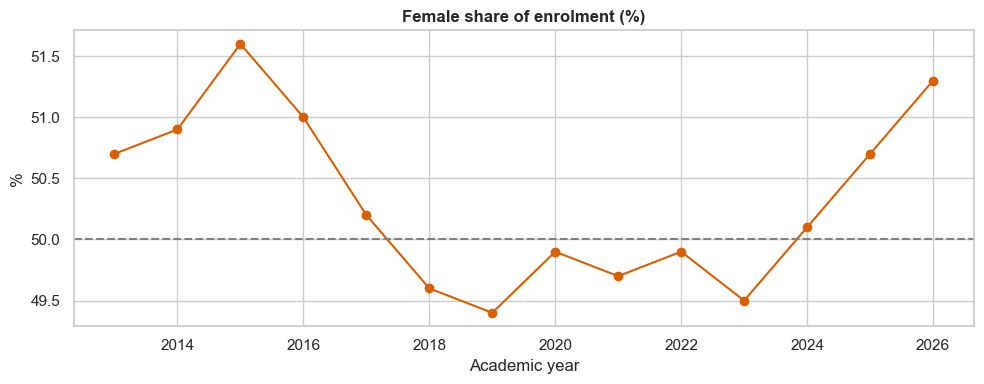

academic_year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
F,8242.0,8189.0,8177.0,7661.0,7398.0,7304.0,7175.0,6966.0,6589.0,6399.0,6321.0,6407.0,6457.0,6491.0
M,8024.0,7903.0,7665.0,7374.0,7336.0,7411.0,7347.0,7002.0,6679.0,6416.0,6437.0,6380.0,6290.0,6165.0
female_share_%,50.7,50.9,51.6,51.0,50.2,49.6,49.4,49.9,49.7,49.9,49.5,50.1,50.7,51.3


In [11]:
gender = panel.groupby("academic_year")[["F", "M"]].sum()
gender["female_share_%"] = (gender["F"] / (gender["F"] + gender["M"]) * 100).round(1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(gender.index, gender["female_share_%"], marker="o", color="#d95f02")
ax.axhline(50, ls="--", color="grey"); ax.set_title("Female share of enrolment (%)")
ax.set_xlabel("Academic year"); ax.set_ylabel("%"); plt.tight_layout(); save(fig, "04_female_share"); plt.show()
gender.T

2013 -> 2026: 16 continuing, 37 closed, 31 new programmes


,students
Continuing programmes (change),-474
Programmes closed after 2013,-9611
New programmes since 2013,6475
Net change,-3610


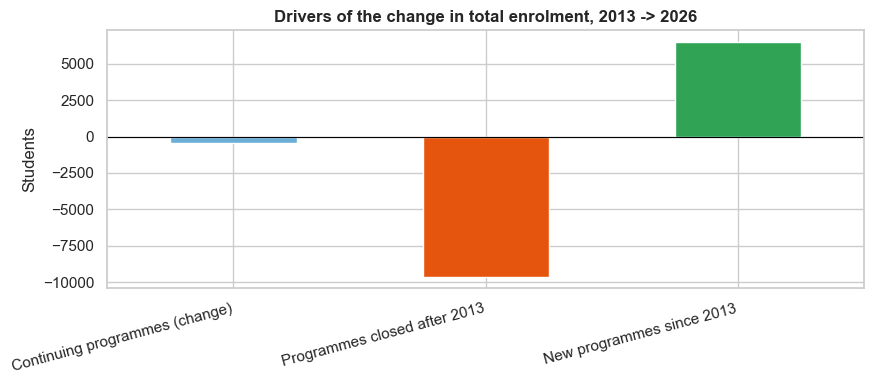

In [12]:
# Where did the decline come from? Split programmes into continuing / closed / new between first and last year
a = panel[panel.academic_year == first_y].set_index("course_name")["total"]
b = panel[panel.academic_year == last_y].set_index("course_name")["total"]
continuing = a.index.intersection(b.index)
closed = a.index.difference(b.index)
new = b.index.difference(a.index)

decomp = pd.Series({
    "Continuing programmes (change)": (b[continuing] - a[continuing]).sum(),
    f"Programmes closed after {first_y}": -a[closed].sum(),
    f"New programmes since {first_y}": b[new].sum(),
})
decomp["Net change"] = decomp.sum()
print(f"{first_y} -> {last_y}: {len(continuing)} continuing, {len(closed)} closed, {len(new)} new programmes")
display(decomp.to_frame("students"))

fig, ax = plt.subplots(figsize=(9, 4))
decomp.iloc[:3].plot.bar(ax=ax, color=["#6baed6", "#e6550d", "#31a354"])
ax.axhline(0, color="black", lw=0.8); ax.set_title(f"Drivers of the change in total enrolment, {first_y} -> {last_y}")
ax.set_ylabel("Students"); plt.xticks(rotation=15, ha="right"); plt.tight_layout(); save(fig, "05_decline_drivers"); plt.show()

In [13]:
# Concentration: how dependent is the total on a few programmes?
share = (panel.pivot_table(index="academic_year", columns="course_name", values="total")
              .apply(lambda r: r.nlargest(3).sum() / r.sum() * 100, axis=1))
print("Share of total enrolment held by the 3 largest programmes (%):")
print(share.round(1).to_string())
print("\nLargest programme overall:", top.index[0], f"({top.iloc[0] / top.sum() * 100:.1f}% of all enrolments)")

Share of total enrolment held by the 3 largest programmes (%):
academic_year
2013    27.4
2014    25.7
2015    25.6
2016    25.3
2017    25.9
2018    27.5
2019    27.9
2020    29.0
2021    29.8
2022    30.9
2023    31.1
2024    31.3
2025    31.7
2026    32.0

Largest programme overall: DIPLOMA IN NURSING (15.9% of all enrolments)


In [14]:
# Statistical checks
# (a) Is there a significant linear trend in total enrolment?
lr = stats.linregress(total_by_year.index, total_by_year.values)
print(f"Trend 2013-2026: {lr.slope:,.0f} students/year, R2 = {lr.rvalue**2:.2f}, p = {lr.pvalue:.4f}")
lr2 = stats.linregress(total_by_year.loc[2023:].index, total_by_year.loc[2023:].values)
print(f"Trend 2023-2026: {lr2.slope:,.0f} students/year (p = {lr2.pvalue:.3f}) -> decline has levelled off" if lr2.pvalue > 0.05
      else f"Trend 2023-2026: {lr2.slope:,.0f} students/year (p = {lr2.pvalue:.3f})")

# (b) Is this year's enrolment predictable from last year's? (justifies the predictive model)
pp = panel.merge(panel[["course_name", "academic_year", "total"]].assign(academic_year=lambda d: d.academic_year + 1)
                 .rename(columns={"total": "lag1"}), on=["course_name", "academic_year"]).dropna(subset=["lag1"])
r, p = stats.pearsonr(np.log(pp["total"]), np.log(pp["lag1"]))
print(f"Correlation of log(enrolment) with log(last year's enrolment): r = {r:.3f} (p < 0.001)" if p < 0.001 else f"r = {r:.3f}, p = {p:.3f}")

# (c) Difference in growth between schools (Kruskal-Wallis on year-on-year growth)
pp["growth"] = pp["total"] / pp["lag1"] - 1
groups = [g_["growth"].values for _, g_ in pp.groupby("school_latest") if len(g_) >= 5]
h, pk = stats.kruskal(*groups)
print(f"Year-on-year growth differs across schools? Kruskal-Wallis H = {h:.1f}, p = {pk:.4f}")

Trend 2013-2026: -311 students/year, R2 = 0.95, p = 0.0000
Trend 2023-2026: -35 students/year (p = 0.210) -> decline has levelled off
Correlation of log(enrolment) with log(last year's enrolment): r = 0.849 (p < 0.001)
Year-on-year growth differs across schools? Kruskal-Wallis H = 47.3, p = 0.0000


In [15]:
# Feature engineering: lags and history of each programme (all use ONLY earlier years)
base = panel[["course_name", "academic_year", "total", "female_share"]]
feat = panel.copy()
for i in (1, 2, 3):
    s = base.copy()
    s["academic_year"] += i
    s = s.rename(columns={"total": f"lag{i}", "female_share": f"fs_lag{i}"})
    cols = ["course_name", "academic_year", f"lag{i}"] + (["fs_lag1"] if i == 1 else [])
    feat = feat.merge(s[cols], on=["course_name", "academic_year"], how="left")

feat["roll3"] = feat[["lag1", "lag2", "lag3"]].mean(axis=1)
feat["hist_years"] = feat.groupby("course_name").cumcount()       # years of history before this year

m = feat.dropna(subset=["lag1"]).copy()
m["log_lag1"] = np.log(m["lag1"])
m["momentum"] = np.log(m["lag1"] / m["lag2"]).fillna(0)           # last year's growth
m["has_lag2"] = m["lag2"].notna().astype(int)
m["vs_roll3"] = np.log(m["roll3"] / m["lag1"])
m["fs_lag1"] = m["fs_lag1"].fillna(m["fs_lag1"].median())
m["y"] = np.log(m["total"] / m["lag1"])                            # target: growth ratio (log)

school_dummies = pd.get_dummies(m["school_latest"], prefix="sch").astype(int)
FEATURES = ["log_lag1", "momentum", "has_lag2", "vs_roll3", "fs_lag1", "hist_years"]
X = pd.concat([m[FEATURES], school_dummies], axis=1)

train = m["academic_year"] <= 2023
test = m["academic_year"] >= 2024
print(f"Train rows: {train.sum()} (<=2023) | Test rows: {test.sum()} (2024-2026)")

Train rows: 554 (<=2023) | Test rows: 132 (2024-2026)


In [16]:
def metrics(y_true, y_pred):
    err = y_true - y_pred
    return {"MAE": np.mean(np.abs(err)),
            "RMSE": np.sqrt(np.mean(err ** 2)),
            "MAPE_%": np.mean(np.abs(err) / y_true) * 100,
            "WAPE_%": np.sum(np.abs(err)) / np.sum(y_true) * 100,
            "MedAPE_%": np.median(np.abs(err) / y_true) * 100}

models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05,
                                                   subsample=0.8, random_state=SEED),
}
y_test_true = m.loc[test, "total"].values
lag_test = m.loc[test, "lag1"].values

results = {"Naive (last year)": metrics(y_test_true, lag_test)}
preds = {"Naive (last year)": lag_test}
for name, mdl in models.items():
    mdl.fit(X[train], m.loc[train, "y"])
    p = lag_test * np.exp(mdl.predict(X[test]))
    preds[name] = p
    results[name] = metrics(y_test_true, p)

res = pd.DataFrame(results).T.round(2).sort_values("MAE")
res

,MAE,RMSE,MAPE_%,WAPE_%,MedAPE_%
Naive (last year),28.12,47.84,74.77,9.83,4.32
Gradient Boosting,52.96,115.57,16.68,18.50,12.97
Random Forest,55.84,128.96,17.91,19.51,14.09
Ridge,85.34,161.47,42.97,29.82,31.74


In [17]:
# Where do the models help? Compare established programmes with young (ramping-up) ones
seg = pd.DataFrame({"actual": y_test_true, "hist": m.loc[test, "hist_years"].values})
for k, p in preds.items():
    seg[k] = p
seg["segment"] = np.where(seg["hist"] >= 3, "Established (3+ years of history)", "Young (<3 years of history)")
rows = []
for sname, gp in seg.groupby("segment"):
    for k in preds:
        mt = metrics(gp["actual"].values, gp[k].values)
        rows.append((sname, k, len(gp), mt["MAE"], mt["WAPE_%"], mt["MedAPE_%"]))
seg_res = pd.DataFrame(rows, columns=["segment", "model", "n", "MAE", "WAPE_%", "MedAPE_%"]).round(2)
seg_res

,segment,model,n,MAE,WAPE_%,MedAPE_%
0,Established (3+ years of history),Naive (last year),119,23.03,7.83,4.11
1,Established (3+ years of history),Ridge,119,89.40,30.40,31.81
2,Established (3+ years of history),Random Forest,119,58.10,19.76,14.23
3,Established (3+ years of history),Gradient Boosting,119,53.60,18.23,12.65
4,Young (<3 years of history),Naive (last year),13,74.69,34.87,36.36
5,Young (<3 years of history),Ridge,13,48.26,22.53,14.32
6,Young (<3 years of history),Random Forest,13,35.20,16.43,13.56
7,Young (<3 years of history),Gradient Boosting,13,47.09,21.98,13.23


Lowest MAE (students):   Naive (last year)
Lowest median APE (%):   Naive (last year)

How to read this: MAE/WAPE are dominated by the few very large programmes (Nursing, Business Management),
where 'same as last year' is hard to beat. MAPE is distorted by tiny programmes. The segment table above shows
whether the models add value for programmes with a short history.


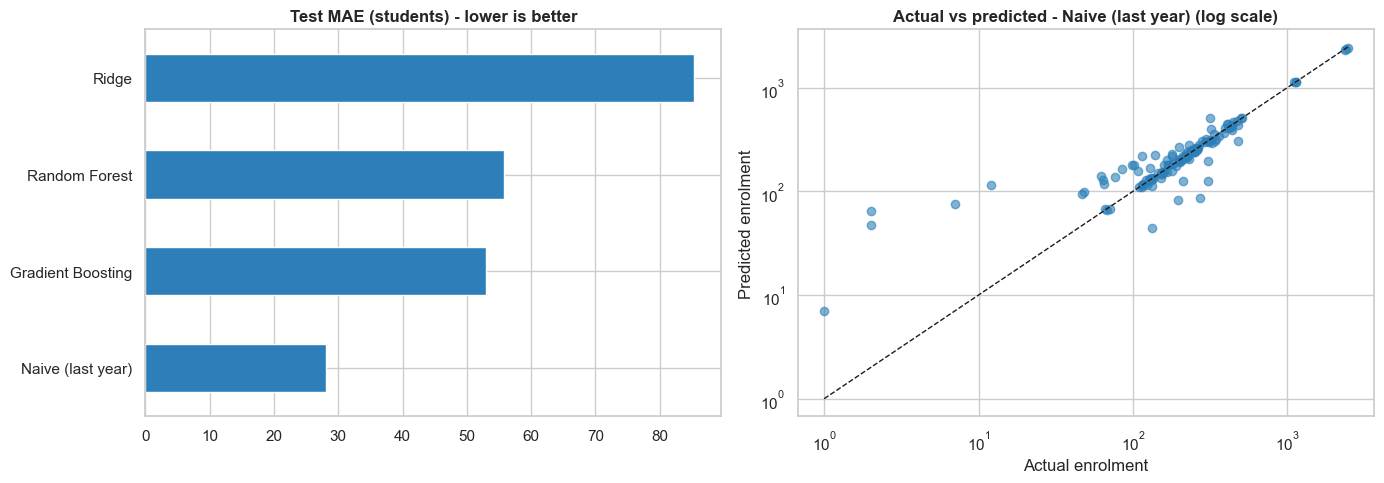

In [18]:
best_name = res.index[0]
base_mae = res.loc["Naive (last year)", "MAE"]
print("Lowest MAE (students):  ", best_name)
print("Lowest median APE (%):  ", res["MedAPE_%"].idxmin())
print()
print("How to read this: MAE/WAPE are dominated by the few very large programmes (Nursing, Business Management),")
print("where 'same as last year' is hard to beat. MAPE is distorted by tiny programmes. The segment table above shows")
print("whether the models add value for programmes with a short history.")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
res["MAE"].sort_values().plot.barh(ax=ax[0], color="#2c7fb8"); ax[0].set_title("Test MAE (students) - lower is better")
mx = max(y_test_true.max(), preds[best_name].max())
ax[1].scatter(y_test_true, preds[best_name], alpha=0.6, color="#2c7fb8")
ax[1].plot([1, mx], [1, mx], "k--", lw=1); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("Actual enrolment"); ax[1].set_ylabel("Predicted enrolment"); ax[1].set_title(f"Actual vs predicted - {best_name} (log scale)")
plt.tight_layout(); save(fig, "06_model_comparison"); plt.show()

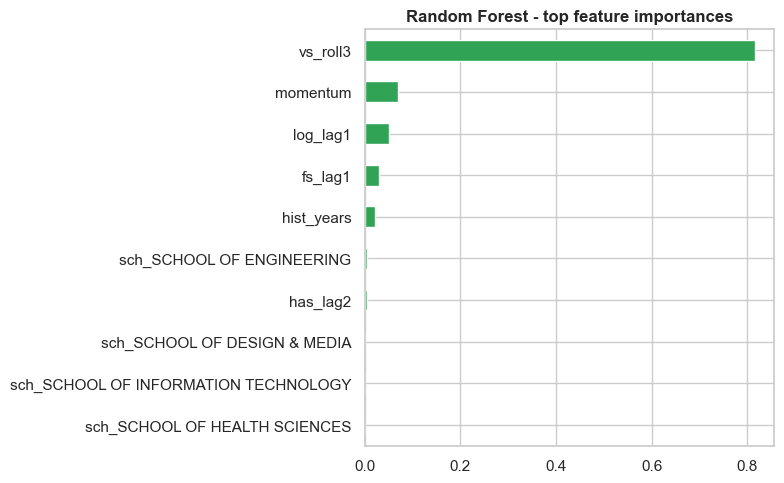

In [19]:
# Which features matter? (Random Forest importance)
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
imp.tail(10).plot.barh(ax=ax, color="#31a354"); ax.set_title("Random Forest - top feature importances")
plt.tight_layout(); save(fig, "07_feature_importance"); plt.show()

In [20]:
# --- forecasting methods (pure numpy) ---
def f_naive(y, h):  return np.repeat(y[-1], h)
def f_mean3(y, h):  return np.repeat(y[-3:].mean(), h)
def f_drift(y, h):  return np.maximum(y[-1] + (y[-1] - y[0]) / (len(y) - 1) * np.arange(1, h + 1), 0)
def f_drift3(y, h): return np.maximum(y[-1] + (y[-1] - y[-4]) / 3 * np.arange(1, h + 1), 0)

def f_holt(y, h):
    # Holt linear exponential smoothing with damped trend; parameters chosen by one-step SSE grid search
    best = (np.inf, None)
    for a in np.linspace(0.1, 0.9, 9):
        for b in np.linspace(0.05, 0.5, 10):
            for phi in (0.8, 0.9, 0.98):
                lvl, tr, sse = y[0], y[1] - y[0], 0.0
                for x in y[1:]:
                    pred = lvl + phi * tr
                    sse += (x - pred) ** 2
                    new = a * x + (1 - a) * pred
                    tr = b * (new - lvl) + (1 - b) * phi * tr
                    lvl = new
                if sse < best[0]:
                    best = (sse, (lvl, tr, phi))
    lvl, tr, phi = best[1]
    steps = np.cumsum(phi ** np.arange(1, h + 1))
    return np.maximum(lvl + steps * tr, 0)

METHODS = {"Naive": f_naive, "Mean of last 3": f_mean3, "Drift": f_drift,
           "Drift (last 3 yrs)": f_drift3, "Holt (damped)": f_holt}
H = 3
LAST = YEARS[-1]

def backtest(series_dict, origins, methods=METHODS, horizon=H):
    # series_dict: {name: pd.Series indexed by year}. Returns tidy table of forecasts vs actuals.
    rows = []
    for name, s in series_dict.items():
        for o in origins:
            hist = s.loc[:o].dropna()
            if len(hist) < 5 or hist.index[-1] != o:
                continue
            for h in range(1, min(horizon, LAST - o) + 1):
                if (o + h) not in s.index or np.isnan(s.loc[o + h]):
                    continue
                for mname, fn in methods.items():
                    rows.append((name, mname, o, h, s.loc[o + h], fn(hist.values, h)[-1]))
    bt = pd.DataFrame(rows, columns=["series", "method", "origin", "h", "actual", "forecast"])
    bt["abs_err"] = (bt.actual - bt.forecast).abs()
    bt["rel_err"] = (bt.actual - bt.forecast) / bt.forecast.replace(0, np.nan)
    bt["ape"] = bt.abs_err / bt.actual
    return bt

In [21]:
# --- (A) Total enrolment: back-test from origins 2018..2025 ---
bt_total = backtest({"Total": total_by_year}, origins=range(2018, LAST))
tot_scores = bt_total.groupby("method").agg(MAE=("abs_err", "mean"), MAPE=("ape", lambda x: x.mean() * 100)).round(2).sort_values("MAE")
print("Back-test on TOTAL enrolment (origins 2018-2025, horizons 1-3):")
display(tot_scores)
best_total = tot_scores.index[0]
print("Selected method for total enrolment:", best_total)

Back-test on TOTAL enrolment (origins 2018-2025, horizons 1-3):


,MAE,MAPE
method,,
Drift,463.52,3.59
Naive,522.19,3.99
Holt (damped),528.12,4.08
Drift (last 3 yrs),569.16,4.42
Mean of last 3,814.11,6.25


Selected method for total enrolment: Drift


,forecast,lower_80,upper_80,flat_scenario
year,,,,
2027,12378.0,12029.0,12728.0,12656
2028,12101.0,11408.0,12794.0,12656
2029,11823.0,10844.0,12802.0,12656


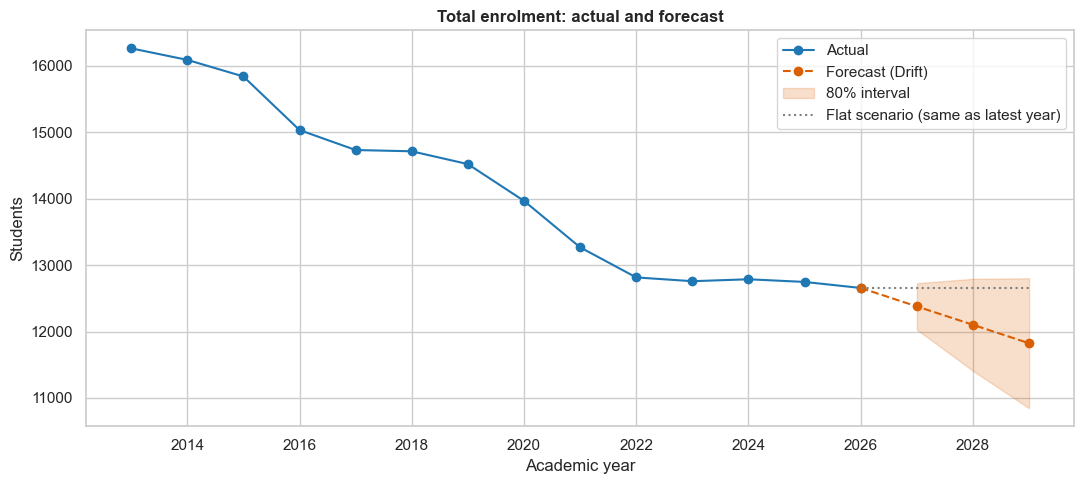

In [22]:
# --- (B) Forecast total enrolment 2027-2029 with 80% band from back-test errors ---
rmse_h = bt_total[bt_total.method == best_total].groupby("h")["abs_err"].apply(lambda e: np.sqrt((e ** 2).mean()))
fc_years = [LAST + i for i in range(1, H + 1)]
fc = METHODS[best_total](total_by_year.values.astype(float), H)
Z80 = 1.2816
total_fc = pd.DataFrame({"forecast": fc.round(0), "lower_80": (fc - Z80 * rmse_h.reindex(range(1, H + 1)).values).round(0),
                         "upper_80": (fc + Z80 * rmse_h.reindex(range(1, H + 1)).values).round(0)}, index=fc_years)
total_fc["flat_scenario"] = total_by_year.iloc[-1]      # "nothing changes from the latest year" (naive)
total_fc.index.name = "year"
display(total_fc)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(total_by_year.index, total_by_year.values, marker="o", color="#1f77b4", label="Actual")
ax.plot([LAST] + fc_years, [total_by_year.iloc[-1]] + list(total_fc.forecast), marker="o", ls="--", color="#d95f02", label=f"Forecast ({best_total})")
ax.fill_between(fc_years, total_fc.lower_80, total_fc.upper_80, color="#d95f02", alpha=0.2, label="80% interval")
ax.plot([LAST] + fc_years, [total_by_year.iloc[-1]] * (H + 1), ls=":", color="grey", label="Flat scenario (same as latest year)")
ax.set_title("Total enrolment: actual and forecast"); ax.set_xlabel("Academic year"); ax.set_ylabel("Students"); ax.legend()
plt.tight_layout(); save(fig, "08_total_forecast"); plt.show()
total_fc.to_csv("outputs/forecast_total_enrolment.csv")

In [23]:
# --- (C) Programme-level forecasts ---
wide = panel.pivot_table(index="academic_year", columns="course_name", values="total").reindex(YEARS)

# "Active" programmes = running with students in each of the last 8 years (enough history to forecast)
recent = YEARS[-8:]
active = [c for c in wide.columns if wide.loc[recent, c].notna().all()]
cover = wide.loc[LAST, active].sum() / wide.loc[LAST].sum() * 100
print(f"Programmes with 8 continuous recent years: {len(active)} of {wide.shape[1]}  "
      f"(they cover {cover:.1f}% of {LAST} enrolment)")

bt_c = backtest({c: wide[c] for c in active}, origins=[2022, 2023])
# select by WAPE = total absolute error / total actual students (weights big programmes by their size, robust to tiny ones)
sc = (bt_c.groupby("method")
          .apply(lambda d: pd.Series({"MAE": d.abs_err.mean(), "WAPE_%": d.abs_err.sum() / d.actual.sum() * 100,
                                      "median_APE_%": d.ape.median() * 100}))
          .round(2).sort_values("WAPE_%"))
print("\nBack-test across programmes (origins 2022 & 2023, horizons 1-3):")
display(sc)
best_course_method = sc.index[0]
print("Selected method for programme-level forecasts:", best_course_method)

Programmes with 8 continuous recent years: 29 of 94  (they cover 70.1% of 2026 enrolment)

Back-test across programmes (origins 2022 & 2023, horizons 1-3):


,MAE,WAPE_%,median_APE_%
method,,,
Naive,29.97,9.03,4.59
Holt (damped),36.91,11.12,8.32
Mean of last 3,38.83,11.70,7.75
Drift (last 3 yrs),42.54,12.82,9.75
Drift,49.05,14.78,13.46


Selected method for programme-level forecasts: Naive


In [24]:
# relative uncertainty by horizon from the back-test
rel_sd = bt_c[bt_c.method == best_course_method].groupby("h")["rel_err"].apply(lambda e: np.sqrt((e ** 2).mean()))
print("Typical relative forecast error by horizon:", (rel_sd * 100).round(1).to_dict(), "(%)")

rows = []
for c in active:
    y = wide[c].dropna().values.astype(float)
    f = METHODS[best_course_method](y, H)
    for i, yr in enumerate(fc_years):
        s = rel_sd.reindex(range(1, H + 1)).values[i]
        rows.append((c, latest_school[c], yr, f[i], max(f[i] * (1 - Z80 * s), 0), f[i] * (1 + Z80 * s)))
course_fc = pd.DataFrame(rows, columns=["course_name", "school", "year", "forecast", "lower_80", "upper_80"]).round(0)
course_fc.to_csv("outputs/forecast_by_programme.csv", index=False)

wide_fc = course_fc.pivot(index="course_name", columns="year", values="forecast")
wide_fc.insert(0, f"{LAST} actual", wide.loc[LAST, active])
wide_fc["change_to_2029_%"] = ((wide_fc[fc_years[-1]] / wide_fc[f"{LAST} actual"] - 1) * 100).round(1)

# Trend scenario: "what if the average change of the last 3 years simply continues?" - used as an early-warning signal,
# because the back-test winner (naive) is flat by construction when demand has been stable
trend_2029 = pd.Series({c: f_drift3(wide[c].dropna().values.astype(float), H)[-1] for c in active}).round(0)
wide_fc[f"trend scenario {fc_years[-1]}"] = trend_2029
wide_fc["trend_change_%"] = ((trend_2029 / wide_fc[f"{LAST} actual"] - 1) * 100).round(1)
wide_fc.to_csv("outputs/forecast_by_programme_wide.csv")
wide_fc.sort_values(f"{LAST} actual", ascending=False).head(15)

Typical relative forecast error by horizon: {1: 9.4, 2: 19.8, 3: 30.9} (%)


year,2026 actual,2027,2028,2029,change_to_2029_%,trend scenario 2029,trend_change_%
course_name,,,,,,,
DIPLOMA IN NURSING,2463.0,2463.0,2463.0,2463.0,0.0,2610.0,6.0
DIPLOMA IN BUSINESS MANAGEMENT,1107.0,1107.0,1107.0,1107.0,0.0,1076.0,-2.8
DIPLOMA IN BUSINESS & FINANCIAL TECHNOLOGY,477.0,477.0,477.0,477.0,0.0,590.0,23.7
DIPLOMA IN INFORMATION TECHNOLOGY,430.0,430.0,430.0,430.0,0.0,452.0,5.1
DIPLOMA IN CYBERSECURITY & DIGITAL FORENSICS,344.0,344.0,344.0,344.0,0.0,386.0,12.2
DIPLOMA IN ROBOTICS & MECHATRONICS,325.0,325.0,325.0,325.0,0.0,332.0,2.2
COMMON ENGINEERING PROGRAMME,318.0,318.0,318.0,318.0,0.0,193.0,-39.3
DIPLOMA IN ACCOUNTANCY & FINANCE,259.0,259.0,259.0,259.0,0.0,260.0,0.4
DIPLOMA IN PHARMACEUTICAL SCIENCE,259.0,259.0,259.0,259.0,0.0,267.0,3.1


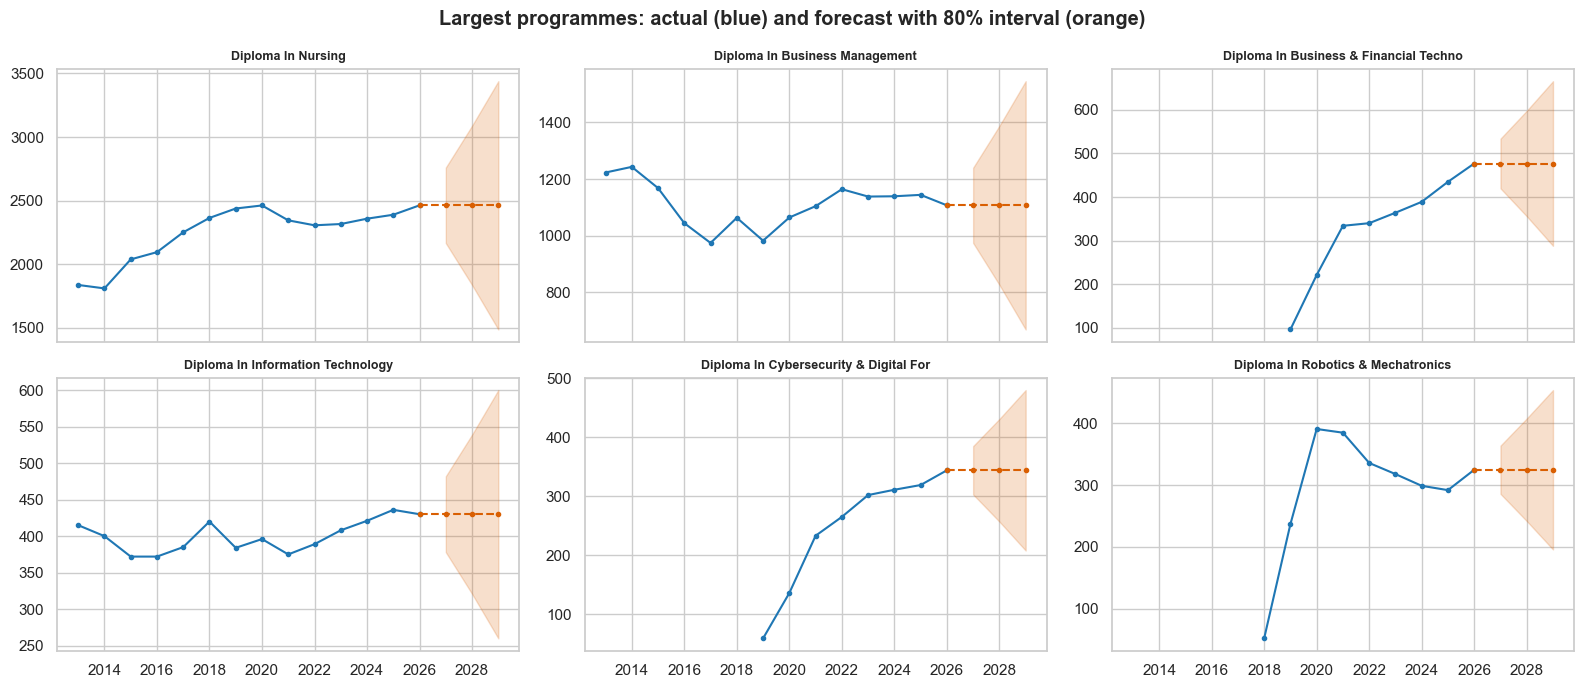

In [25]:
# plot the 6 largest programmes: history + forecast
big = wide.loc[LAST, active].sort_values(ascending=False).head(6).index
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for ax, c in zip(axes.ravel(), big):
    ax.plot(wide.index, wide[c], marker="o", ms=3, color="#1f77b4")
    d = course_fc[course_fc.course_name == c]
    ax.plot([LAST] + fc_years, [wide.loc[LAST, c]] + list(d.forecast), ls="--", marker="o", ms=3, color="#d95f02")
    ax.fill_between(fc_years, d.lower_80, d.upper_80, color="#d95f02", alpha=0.2)
    ax.set_title(c.title()[:38], fontsize=9)
fig.suptitle("Largest programmes: actual (blue) and forecast with 80% interval (orange)", fontweight="bold")
plt.tight_layout(); save(fig, "09_programme_forecasts"); plt.show()

In [26]:
# forecast by (latest) school = sum of its active programmes
school_tbl = (course_fc.pivot_table(index="school", columns="year", values="forecast", aggfunc="sum")
              .assign(**{f"{LAST} actual": wide.loc[LAST, active].groupby(latest_school.reindex(active)).sum()}))
school_tbl = school_tbl[[f"{LAST} actual"] + fc_years]
school_tbl["change_to_2029_%"] = ((school_tbl[fc_years[-1]] / school_tbl[f"{LAST} actual"] - 1) * 100).round(1)
school_tbl.sort_values(f"{LAST} actual", ascending=False)

year,2026 actual,2027,2028,2029,change_to_2029_%
school,,,,,
SCHOOL OF HEALTH & SOCIAL SCIENCES,2534.0,2534.0,2534.0,2534.0,0.0
SCHOOL OF BUSINESS MANAGEMENT,2505.0,2505.0,2505.0,2505.0,0.0
SCHOOL OF INFORMATION TECHNOLOGY,1471.0,1471.0,1471.0,1471.0,0.0
SCHOOL OF ENGINEERING,1220.0,1220.0,1220.0,1220.0,0.0
SCHOOL OF APPLIED SCIENCE,742.0,742.0,742.0,742.0,0.0
SCHOOL OF DESIGN & MEDIA,404.0,404.0,404.0,404.0,0.0


In [27]:
dec = total_by_year
peak_year = dec.idxmax()
print(f"1. Total enrolment peaked in {peak_year} ({dec.max():,}) and was {dec.iloc[-1]:,} in {LAST} "
      f"({(dec.iloc[-1] / dec.max() - 1) * 100:.1f}% vs peak).")
print(f"2. {abs(decomp.iloc[1]):,.0f} of the lost places came from {len(closed)} closed programmes, while continuing programmes changed by "
      f"{decomp.iloc[0]:+,.0f} and new programmes added {decomp.iloc[2]:+,.0f}.")
print(f"3. The 3 largest programmes hold {share.iloc[-1]:.0f}% of {LAST} enrolment, so demand is concentrated.")
print(f"4. Enrolment is highly persistent (corr. with last year = {r:.2f}); the 'same as last year' baseline has the lowest MAE "
      f"({res.loc['Naive (last year)', 'MAE']:.1f} students) on 2024-2026, so ML models are only worth using for young / ramping-up programmes.")
print(f"5. Forecast total ({best_total}): " + ", ".join(f"{y}: {int(v):,}" for y, v in total_fc.forecast.items())
      + f" (80% band in {fc_years[-1]}: {int(total_fc.lower_80.iloc[-1]):,}-{int(total_fc.upper_80.iloc[-1]):,}).")

1. Total enrolment peaked in 2013 (16,266) and was 12,656 in 2026 (-22.2% vs peak).
2. 9,611 of the lost places came from 37 closed programmes, while continuing programmes changed by -474 and new programmes added +6,475.
3. The 3 largest programmes hold 32% of 2026 enrolment, so demand is concentrated.
4. Enrolment is highly persistent (corr. with last year = 0.85); the 'same as last year' baseline has the lowest MAE (28.1 students) on 2024-2026, so ML models are only worth using for young / ramping-up programmes.
5. Forecast total (Drift): 2027: 12,378, 2028: 12,101, 2029: 11,823 (80% band in 2029: 10,844-12,802).


In [28]:
GROW_T, DECLINE_T = 5.0, -10.0       # % change 2026 -> 2029 that triggers an action

vol = (wide.loc[recent, active].pct_change().std() * 100).round(1)           # volatility of yoy growth
rec = wide_fc[[f"{LAST} actual", fc_years[-1], f"trend scenario {fc_years[-1]}", "trend_change_%"]].copy()
rec.columns = [f"{LAST} actual", f"{fc_years[-1]} forecast", f"{fc_years[-1]} trend scenario", "change_%"]   # change_% = trend scenario vs actual
rec["volatility_%"] = vol
rec["school"] = latest_school.reindex(rec.index)
rec["80% range (2029)"] = (course_fc[course_fc.year == fc_years[-1]].set_index("course_name")
                           .apply(lambda r: f"{int(r.lower_80)}-{int(r.upper_80)}", axis=1))

def action(r):
    if r["change_%"] <= DECLINE_T:
        return "Review: plan smaller intake / consider consolidating"
    if r["change_%"] >= GROW_T:
        return "Grow: reserve extra capacity / staffing"
    return "Maintain current capacity"
rec["recommended_action"] = rec.apply(action, axis=1)
rec = rec.sort_values(f"{LAST} actual", ascending=False)
rec.to_csv("outputs/recommendations.csv")

display(rec["recommended_action"].value_counts().to_frame("programmes"))
rec.head(15)

,programmes
recommended_action,
Maintain current capacity,14
Review: plan smaller intake / consider consolidating,10
Grow: reserve extra capacity / staffing,5


,2026 actual,2029 forecast,2029 trend scenario,change_%,volatility_%,school,80% range (2029),recommended_action
course_name,,,,,,,,
DIPLOMA IN NURSING,2463.0,2463.0,2610.0,6.0,2.6,SCHOOL OF HEALTH & SOCIAL SCIENCES,1487-3439,Grow: reserve extra capacity / staffing
DIPLOMA IN BUSINESS MANAGEMENT,1107.0,1107.0,1076.0,-2.8,4.2,SCHOOL OF BUSINESS MANAGEMENT,668-1546,Maintain current capacity
DIPLOMA IN BUSINESS & FINANCIAL TECHNOLOGY,477.0,477.0,590.0,23.7,46.7,SCHOOL OF INFORMATION TECHNOLOGY,288-666,Grow: reserve extra capacity / staffing
DIPLOMA IN INFORMATION TECHNOLOGY,430.0,430.0,452.0,5.1,3.7,SCHOOL OF INFORMATION TECHNOLOGY,260-600,Grow: reserve extra capacity / staffing
DIPLOMA IN CYBERSECURITY & DIGITAL FORENSICS,344.0,344.0,386.0,12.2,48.6,SCHOOL OF INFORMATION TECHNOLOGY,208-480,Grow: reserve extra capacity / staffing
DIPLOMA IN ROBOTICS & MECHATRONICS,325.0,325.0,332.0,2.2,26.6,SCHOOL OF ENGINEERING,196-454,Maintain current capacity
COMMON ENGINEERING PROGRAMME,318.0,318.0,193.0,-39.3,32.1,SCHOOL OF ENGINEERING,192-444,Review: plan smaller intake / consider consoli...
DIPLOMA IN ACCOUNTANCY & FINANCE,259.0,259.0,260.0,0.4,5.2,SCHOOL OF BUSINESS MANAGEMENT,156-362,Maintain current capacity
DIPLOMA IN PHARMACEUTICAL SCIENCE,259.0,259.0,267.0,3.1,35.4,SCHOOL OF APPLIED SCIENCE,156-362,Maintain current capacity


In [29]:
print("Programmes forecast to shrink the most:")
display(rec.sort_values("change_%").head(5)[[f"{LAST} actual", f"{fc_years[-1]} forecast", f"{fc_years[-1]} trend scenario", "change_%", "80% range (2029)"]])
print("Programmes forecast to grow the most:")
display(rec.sort_values("change_%", ascending=False).head(5)[[f"{LAST} actual", f"{fc_years[-1]} forecast", f"{fc_years[-1]} trend scenario", "change_%", "80% range (2029)"]])

Programmes forecast to shrink the most:


,2026 actual,2029 forecast,2029 trend scenario,change_%,80% range (2029)
course_name,,,,,
DIPLOMA IN DIGITAL GAME ART & DESIGN,1.0,1.0,0.0,-100.0,1-1
DIPLOMA IN NANOTECHNOLOGY & MATERIALS SCIENCE,64.0,64.0,0.0,-100.0,39-89
DIPLOMA IN AEROSPACE SYSTEMS & MANAGEMENT,85.0,85.0,0.0,-100.0,51-119
DIPLOMA IN AERONAUTICAL & AEROSPACE TECHNOLOGY,99.0,99.0,0.0,-100.0,60-138
DIPLOMA IN ENGINEERING WITH BUSINESS,102.0,102.0,0.0,-100.0,62-142


Programmes forecast to grow the most:


,2026 actual,2029 forecast,2029 trend scenario,change_%,80% range (2029)
course_name,,,,,
DIPLOMA IN BUSINESS & FINANCIAL TECHNOLOGY,477.0,477.0,590.0,23.7,288-666
DIPLOMA IN CYBERSECURITY & DIGITAL FORENSICS,344.0,344.0,386.0,12.2,208-480
DIPLOMA IN NURSING,2463.0,2463.0,2610.0,6.0,1487-3439
DIPLOMA IN ORAL HEALTH THERAPY,71.0,71.0,75.0,5.6,43-99
DIPLOMA IN INFORMATION TECHNOLOGY,430.0,430.0,452.0,5.1,260-600


In [68]:
import difflib

def predict_enrolment(course_query, target_year, show_plot=True):
    """Forecast enrolment of one programme for 2027-2029 using the method chosen by the back-test."""
    h = int(target_year) - LAST
    if h < 1 or h > H:
        print(f"Please choose a year between {LAST + 1} and {LAST + H} (forecasts are validated for up to {H} years ahead).")
        return None

    # --- find the programme (case-insensitive, partial name allowed) ---
    q = str(course_query).strip().upper()
    names = list(wide.columns)
    exact = [c for c in names if c == q]
    matches = exact or [c for c in names if q in c]
    if not matches:
        close = difflib.get_close_matches(q, names, n=5, cutoff=0.4)
        print(f'No programme found for "{course_query}".')
        if close:
            print("Did you mean:\n  - " + "\n  - ".join(close))
        return None
    if len(matches) > 1:
        print(f'"{course_query}" matches {len(matches)} programmes - please be more specific:')
        print("  - " + "\n  - ".join(matches[:10]))
        return None
    course = matches[0]

    # --- history of that programme ---
    s = wide[course].dropna()
    y = s.values.astype(float)
    last_year = int(s.index[-1])
    if last_year < LAST:
        print(f"{course} was last offered in {last_year} (not in {LAST}), so a forecast is not meaningful.")
        return None

    # --- forecast (method chosen by back-test) + 80% interval + trend scenario ---
    base = METHODS[best_course_method](y, H)[h - 1]
    sd = rel_sd.reindex(range(1, H + 1)).values[h - 1]
    low, high = max(base * (1 - Z80 * sd), 0), base * (1 + Z80 * sd)
    trend = f_drift3(y, H)[h - 1] if len(y) >= 4 else np.nan

    print("=" * 66)
    print(f"Programme : {course.title()}")
    print(f"School    : {latest_school[course].title()}")
    print(f"History   : {len(y)} years of data ({int(s.index[0])}-{last_year}); latest ({LAST}) = {int(y[-1]):,} students")
    print("-" * 66)
    print(f"Predicted enrolment in {target_year}: {int(round(base)):,} students   [method: {best_course_method}]")
    print(f"80% likely range                  : {int(round(low)):,} to {int(round(high)):,}")
    if not np.isnan(trend):
        chg = (trend / y[-1] - 1) * 100
        print(f"Trend scenario (last 3 yrs' average change continues): {int(round(trend)):,} ({chg:+.1f}% vs {LAST})")
        if chg <= DECLINE_T:
            print("Signal    : DECLINING - consider a smaller intake / review the programme")
        elif chg >= GROW_T:
            print("Signal    : GROWING - consider reserving extra capacity")
        else:
            print("Signal    : STABLE - maintain current capacity")
    if len(y) < 8:
        print(f"Warning   : only {len(y)} years of history - treat this forecast with extra caution.")
    print("=" * 66)

    if show_plot:
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.plot(s.index, y, marker="o", color="#1f77b4", label="Actual")
        ax.plot([LAST, target_year], [y[-1], base], ls="--", marker="o", color="#d95f02", label=f"Forecast {target_year}")
        ax.vlines(target_year, low, high, color="#d95f02", lw=6, alpha=0.3, label="80% range")
        ax.set_title(course.title()[:60]); ax.set_xlabel("Academic year"); ax.set_ylabel("Students"); ax.legend()
        plt.tight_layout()
        plt.savefig(f"outputs/prediction_{course.title().replace(' ', '_')[:40]}_{target_year}.png", dpi=150, bbox_inches="tight")
        plt.show()
    return {"programme": course, "year": int(target_year), "forecast": float(base),
            "low_80": float(low), "high_80": float(high), "trend_scenario": float(trend)}

# programmes with enough history to forecast reliably
print("Programmes with 8+ continuous years (best for prediction):")
for c in sorted(active):
    print("  -", c.title())

Programmes with 8+ continuous years (best for prediction):
  - Common Business Programme
  - Common Engineering Programme
  - Common Ict Programme
  - Diploma In Accountancy & Finance
  - Diploma In Aeronautical & Aerospace Technology
  - Diploma In Aerospace Systems & Management
  - Diploma In Architecture
  - Diploma In Banking & Finance
  - Diploma In Biologics & Process Technology
  - Diploma In Biomedical Engineering
  - Diploma In Business & Financial Technology
  - Diploma In Business Management
  - Diploma In Chemical & Pharmaceutical Technology
  - Diploma In Cybersecurity & Digital Forensics
  - Diploma In Digital Game Art & Design
  - Diploma In Engineering With Business
  - Diploma In Food & Beverage Business
  - Diploma In Food Science & Nutrition
  - Diploma In Game Development & Technology
  - Diploma In Hospitality & Tourism Management
  - Diploma In Infocomm & Security
  - Diploma In Information Technology
  - Diploma In Mass Media Management
  - Diploma In Nanotechnol

Enter programme name (or part of it):  nursing
Enter year to predict (2027, 2028 or 2029):  2028


Programme : Diploma In Nursing
School    : School Of Health & Social Sciences
History   : 14 years of data (2013-2026); latest (2026) = 2,463 students
------------------------------------------------------------------
Predicted enrolment in 2028: 2,463 students   [method: Naive]
80% likely range                  : 1,837 to 3,089
Trend scenario (last 3 yrs' average change continues): 2,561 (+4.0% vs 2026)
Signal    : STABLE - maintain current capacity


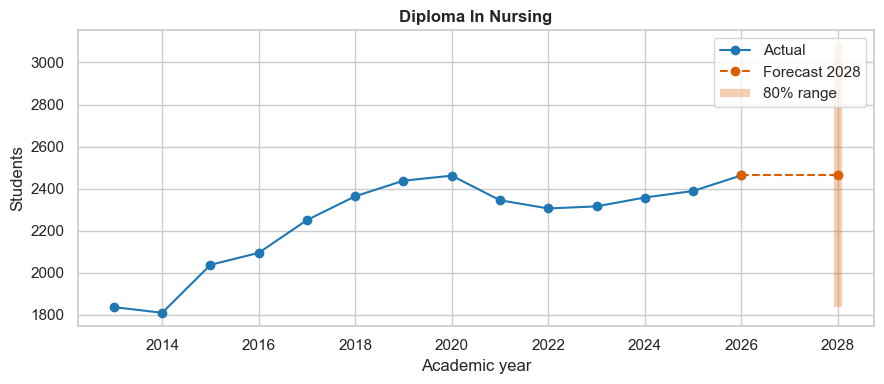

{'programme': 'DIPLOMA IN NURSING',
 'year': 2028,
 'forecast': 2463.0,
 'low_80': 1837.0733049368396,
 'high_80': 3088.9266950631604,
 'trend_scenario': 2561.0}

In [70]:
course_query = input("Enter programme name (or part of it): ")
target_year = int(input("Enter year to predict (2027, 2028 or 2029): "))
predict_enrolment(course_query, target_year)